In [1]:
import time
import tracemalloc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn import metrics

try:
    import hdbscan
except ImportError as exc:
    raise ImportError(
        "Library hdbscan belum terpasang. Jalankan: pip install hdbscan"
    ) from exc

In [2]:
df = pd.read_csv('../data/komdigi_hoaks.csv')

df['teks'] = df['title'].fillna('') + ' ' + df['excerpt'].fillna('')
df = df[df['teks'].str.strip() != ''].reset_index(drop=True)

print(f"Total data bersih siap klasterisasi: {len(df)} baris")
df[['title', 'teks']].head()

Total data bersih siap klasterisasi: 4176 baris


,title,teks
0,[HOAKS] Tautan Pencairan BSU September 2026 Se...,[HOAKS] Tautan Pencairan BSU September 2026 Se...
1,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...
2,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...
3,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...
4,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...


In [3]:
tfidf = TfidfVectorizer(max_features=1000)
X = tfidf.fit_transform(df['teks'])

print("Bentuk matriks data:", X.shape)

Bentuk matriks data: (4176, 1000)


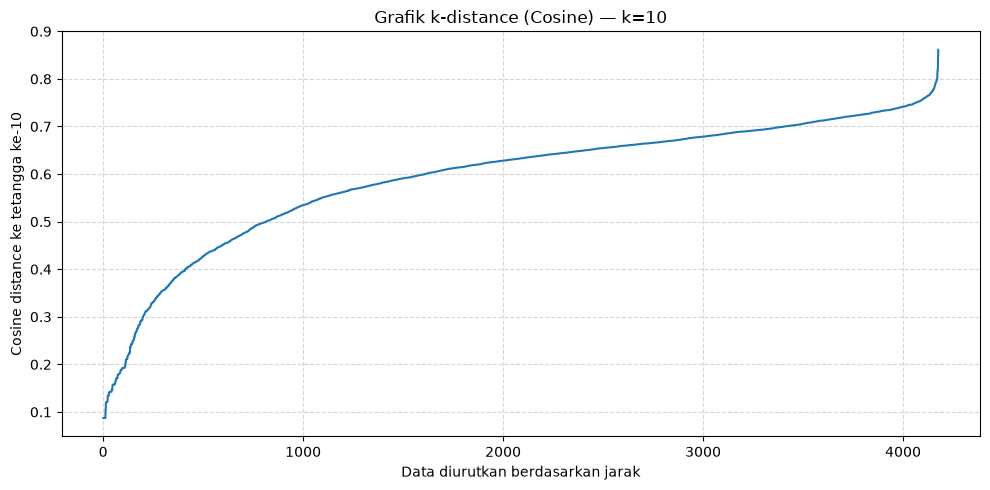

In [4]:
from sklearn.neighbors import NearestNeighbors

K_NEIGHBORS = 10

# Cosine distance ke tetangga ke-K
nn = NearestNeighbors(n_neighbors=K_NEIGHBORS, metric='cosine', algorithm='brute')
nn.fit(X)
distances, _ = nn.kneighbors(X)

# Kolom terakhir adalah jarak ke tetangga ke-K
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(k_distances) + 1), k_distances)
plt.title(f'Grafik k-distance (Cosine) — k={K_NEIGHBORS}')
plt.xlabel('Data diurutkan berdasarkan jarak')
plt.ylabel(f'Cosine distance ke tetangga ke-{K_NEIGHBORS}')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [5]:
# Parameter awal HDBSCAN (dapat diuji/tuning)
MIN_CLUSTER_SIZE = 10
MIN_SAMPLES = 10

# HDBSCAN dengan cosine distance
tracemalloc.start()
waktu_mulai = time.time()

X_dense = X.toarray()

hdbscan_cosine = hdbscan.HDBSCAN(
    min_cluster_size=MIN_CLUSTER_SIZE,
    min_samples=MIN_SAMPLES,
    metric='cosine',
    algorithm='generic',
    cluster_selection_method='eom'
)

labels = hdbscan_cosine.fit_predict(X_dense)
df['cluster_hdbscan_cosine'] = labels

waktu_selesai = time.time()
mem_sekarang, mem_puncak = tracemalloc.get_traced_memory()
tracemalloc.stop()

hasil_jumlah_klaster = len(set(labels)) - (1 if -1 in labels else 0)
jumlah_noise = int(np.sum(labels == -1))
jumlah_data_terklaster = int(np.sum(labels != -1))
proporsi_noise = jumlah_noise / len(labels) * 100 if len(labels) else 0

hasil_waktu = waktu_selesai - waktu_mulai
hasil_memori_mb = mem_puncak / (1024 * 1024)

# Silhouette dihitung hanya untuk data non-noise.
# Skor memerlukan minimal 2 cluster dan kurang dari jumlah sampel.
mask_non_noise = labels != -1
labels_non_noise = labels[mask_non_noise]
X_non_noise = X[mask_non_noise]

if len(np.unique(labels_non_noise)) >= 2 and len(np.unique(labels_non_noise)) < len(labels_non_noise):
    hasil_silhouette = metrics.silhouette_score(
        X_non_noise,
        labels_non_noise,
        metric='cosine'
    )
else:
    hasil_silhouette = np.nan

print("=" * 48)
print("HASIL PENGUJIAN: HDBSCAN COSINE DISTANCE")
print("=" * 48)
print(f"1. Jumlah Klaster       : {hasil_jumlah_klaster} klaster")
print(f"2. Data Noise           : {jumlah_noise} ({proporsi_noise:.2f}%)")
print(f"3. Data dalam Klaster    : {jumlah_data_terklaster}")
print(f"4. Waktu Eksekusi        : {hasil_waktu:.4f} detik")
if np.isnan(hasil_silhouette):
    print("5. Silhouette Score      : tidak dapat dihitung (perlu minimal 2 cluster non-noise)")
else:
    print(f"5. Silhouette Score      : {hasil_silhouette:.4f} (cosine, tanpa noise)")
print(f"6. Memori puncak terukur  : {hasil_memori_mb:.2f} MB")
print("=" * 48)

HASIL PENGUJIAN: HDBSCAN COSINE DISTANCE
1. Jumlah Klaster       : 8 klaster
2. Data Noise           : 3524 (84.39%)
3. Data dalam Klaster    : 652
4. Waktu Eksekusi        : 2.4024 detik
5. Silhouette Score      : 0.3072 (cosine, tanpa noise)
6. Memori puncak terukur  : 364.64 MB


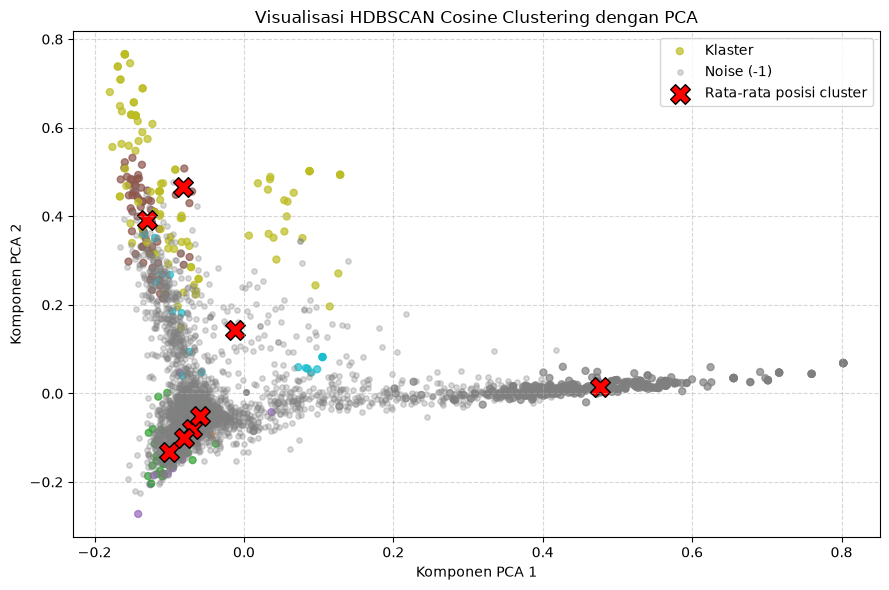

In [6]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_dense)

df['pca1'] = X_pca[:, 0]
df['pca2'] = X_pca[:, 1]

plt.figure(figsize=(9, 6))

non_noise = df[df['cluster_hdbscan_cosine'] != -1]
plt.scatter(
    non_noise['pca1'],
    non_noise['pca2'],
    c=non_noise['cluster_hdbscan_cosine'],
    cmap='tab10',
    s=25,
    alpha=0.7,
    label='Klaster'
)

noise = df[df['cluster_hdbscan_cosine'] == -1]
if not noise.empty:
    plt.scatter(
        noise['pca1'],
        noise['pca2'],
        color='gray',
        s=15,
        alpha=0.3,
        label='Noise (-1)'
    )

for i, c in enumerate(sorted(non_noise['cluster_hdbscan_cosine'].unique())):
    anggota = non_noise[non_noise['cluster_hdbscan_cosine'] == c]
    pusat_x = anggota['pca1'].mean()
    pusat_y = anggota['pca2'].mean()
    plt.scatter(
        pusat_x,
        pusat_y,
        marker='X',
        s=200,
        color='red',
        edgecolors='black',
        label='Rata-rata posisi cluster' if i == 0 else ''
    )

plt.title('Visualisasi HDBSCAN Cosine Clustering dengan PCA')
plt.xlabel('Komponen PCA 1')
plt.ylabel('Komponen PCA 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [7]:
terms = tfidf.get_feature_names_out()
unique_clusters = sorted(df['cluster_hdbscan_cosine'].unique())

print("Kata Kunci Dominan Tiap Klaster HDBSCAN:")
for c in unique_clusters:
    if c == -1:
        nama = "NOISE / OUTLIER"
    else:
        nama = f"Klaster {c}"

    idx = df.index[df['cluster_hdbscan_cosine'] == c].to_numpy()
    mean_tfidf = np.asarray(X[idx].mean(axis=0)).flatten()
    top_terms = [terms[i] for i in mean_tfidf.argsort()[::-1][:7]]
    print(f"[{nama}] ({len(idx)} data): {', '.join(top_terms)}")

Kata Kunci Dominan Tiap Klaster HDBSCAN:
[NOISE / OUTLIER] (3524 data): hoaks, di, video, dan, yang, untuk, tautan
[Klaster 0] (14 data): perampasan, aset, ruu, dpr, baswedan, anies, prabowo
[Klaster 1] (25 data): vaksin, covid, 19, hoaks, dan, dapat, tewas
[Klaster 2] (45 data): ai, probabilitas, persen, intelligence, artificial, hasil, mencapai
[Klaster 3] (25 data): bagi, prabowo, uang, presiden, juta, hoaks, tiktok
[Klaster 4] (65 data): tautan, data, pribadi, telegram, mengarah, meminta, nama
[Klaster 5] (351 data): akun, mengatasnamakan, whatsapp, kabupaten, bupati, hoaks, pj
[Klaster 6] (109 data): lowongan, kerja, tautan, pt, pendaftaran, hoaks, pekerjaan
[Klaster 7] (18 data): undian, berhadiah, bank, mengatasnamakan, tautan, hoaks, 2026
